# Stage 4 — Productionisation & Operations [25 Marks]

This notebook moves the registered model from Stage 3 into production and runs it. Everything here uses the project modules, so the notebook shows evidence and the logic lives in versioned, tested code:

| File | Role |
|---|---|
| `data_prep.py` | Stage 2 loading, cleaning, feature engineering, split and data validation (shared by training, API and monitoring) |
| `app.py` | FastAPI inference service: `/health`, `/predict`, input validation, prediction logging |
| `Dockerfile`, `requirements-api.txt`, `.dockerignore` | Container image for the API |
| `.github/workflows/ci.yml`, `tests/`, `pytest.ini` | CI: install pinned dependencies and run pytest |
| `monitoring.py` | Model export, reference/current samples, Evidently feature drift, PSI prediction drift, governance helpers |
| `retrain.py` | Multi-signal retraining trigger, retraining, re-registration and decision records |
| `requirements.txt` | Pinned dependencies |

The production model is whatever the MLflow alias `hospital-readmission-30d-classifier@production` points to (version 1, the Stage 3 XGBoost pipeline, at the start of this notebook).

In [1]:
import json
import os
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "data_prep.py").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import data_prep as dp
import monitoring as mon
import retrain

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def show_file(path, language=""):
    display(Markdown(f"**`{path}`**\n\n```{language}\n{(ROOT / path).read_text(encoding='utf-8').rstrip()}\n```"))


def run(command, timeout=900, tail=None):
    """Run a shell command from the project root and print its (optionally tail-trimmed) output."""
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, encoding="utf-8",
                            errors="replace", timeout=timeout)
    lines = (result.stdout + result.stderr).rstrip().splitlines()
    if tail and len(lines) > tail:
        print(f"... ({len(lines) - tail} earlier lines omitted)")
        lines = lines[-tail:]
    print("\n".join(lines))
    print(f"[exit code {result.returncode}]")
    return result


splits = dp.prepare_splits()
production = mon.production_version()
print(f"Python {sys.version.split()[0]} | project root: {ROOT}")
print(f"Production model: {mon.REGISTERED_MODEL_NAME} v{production.version} (@{mon.PRODUCTION_ALIAS}), run {production.run_id}")
print({k: v.shape for k, v in splits.items() if k.startswith("X_")})

Python 3.14.7 | project root: C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps
Production model: hospital-readmission-30d-classifier v1 (@production), run c10bb43f1120428d8f1665253cd6d577
{'X_train': (48981, 46), 'X_val': (10496, 46), 'X_test': (10496, 46)}


## Task 4.1 — API Deployment [5 Marks]

### 4.1.1 — FastAPI inference service (/predict + /health + validation) [3]

`app.py` serves the production pipeline:

- **Model loading.** At startup the app loads the model from `MODEL_URI`. By default this is `./model`, a plain copy of the registry version behind `@production` created by `monitoring.export_production_model()`, so the API and the container don't need the MLflow database. `model_info.json` records which registry version was exported. If the model cannot be loaded, the service still starts but reports itself as unhealthy.
- **`GET /health`** returns `200` with the model name and version, or `503` if no model is loaded. This makes it usable as a liveness/readiness probe and as the Docker `HEALTHCHECK`.
- **`POST /predict`** takes **one raw encounter** in the same schema as `diabetic_data.csv` (identifiers and the target excluded). It applies the same `data_prep.engineer_features` used in training and returns the readmission probability, the 0/1 prediction at the 0.5 decision threshold, a risk label, the model version and a request id.
- **Validation (pydantic).** Invalid requests are rejected with `422` before reaching the model:
  - required fields and types;
  - allowed category values (gender, race, age band, `A1Cresult`, `max_glu_serum`, the 21 medication statuses, `change`, `diabetesMed`);
  - numeric ranges matching the source data (e.g. `time_in_hospital` 1–14);
  - an ICD-9 pattern for `diag_1`–`diag_3`;
  - rejection of expired/hospice discharge codes, which Stage 2 excluded from the population;
  - no unknown fields.

  Optional fields (race, payer code, specialty, secondary diagnoses, lab results, medications) may be omitted or null; the pipeline imputes them exactly as in training.

In [2]:
# 4.1.1 — FastAPI inference service (/predict + /health + validation)
# Export the production model to ./model (the artefact served by the API and baked into the Docker image).
model_info = mon.export_production_model()
print(json.dumps(model_info, indent=2))

import app as api

routes = pd.DataFrame(
    [{"method": ",".join(sorted(r.methods)), "path": r.path, "endpoint": r.name}
     for r in api.app.routes if r.path in ("/health", "/predict")]
)
display(routes)

schema = api.Encounter.model_json_schema()
rules = []
for name, spec in schema["properties"].items():
    options = spec.get("anyOf", [spec])
    enum = next((o["enum"] for o in options if "enum" in o), None)
    rule = (f"one of {len(enum)} values: {enum[:4]}{' ...' if len(enum) > 4 else ''}" if enum else
            " ".join(f"{k}={o[k]}" for o in options for k in ("minimum", "maximum", "pattern") if k in o))
    rules.append({"field": name, "required": name in schema.get("required", []), "rule": rule or "free text"})
rules = pd.DataFrame(rules).set_index("field")
print(f"Request schema: {len(rules)} fields, {rules['required'].sum()} required, "
      f"extra fields forbidden = {api.Encounter.model_config.get('extra') == 'forbid'}")
display(rules.head(20))


2026-11-11 13:11:04,426 INFO monitoring: Exported hospital-readmission-30d-classifier v1 (@production) to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\model


{
  "model_name": "hospital-readmission-30d-classifier",
  "model_version": "1",
  "alias": "production",
  "run_id": "c10bb43f1120428d8f1665253cd6d577",
  "exported_at": "2026-11-11T07:41:04.425849+00:00"
}


,method,path,endpoint
0,GET,/health,health
1,POST,/predict,predict


Request schema: 44 fields, 15 required, extra fields forbidden = True


,required,rule
field,,
race,False,"one of 5 values: ['Caucasian', 'AfricanAmerica..."
gender,True,"one of 2 values: ['Female', 'Male']"
age,True,"one of 10 values: ['[0-10)', '[10-20)', '[20-3..."
admission_type_id,True,minimum=1 maximum=8
discharge_disposition_id,True,minimum=1 maximum=30
admission_source_id,True,minimum=1 maximum=26
time_in_hospital,True,minimum=1 maximum=14
payer_code,False,free text
medical_specialty,False,free text


### 4.1.2 — Live request/response demonstrated in-notebook [2]

The API is started as a real `uvicorn` server process on port 8001 and called over HTTP with `requests`:

1. `GET /health`
2. `POST /predict` with a real encounter from the held-out **test** split
3. a batch of further test encounters, which also populates the prediction log used in 4.6.1
4. invalid requests that the validation layer must reject with `422`

In [3]:
# 4.1.2 — Live request/response demonstrated in-notebook
API_PORT = 8001
API_URL = f"http://127.0.0.1:{API_PORT}"
PREDICTION_LOG = ROOT / "logs" / "predictions.jsonl"
PREDICTION_LOG.parent.mkdir(exist_ok=True)

server_env = {**os.environ, "MODEL_URI": str(ROOT / "model"), "PREDICTION_LOG_PATH": str(PREDICTION_LOG)}
server_log = open(ROOT / "logs" / "uvicorn_demo.log", "w", encoding="utf-8")
server = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1", "--port", str(API_PORT)],
    cwd=ROOT, env=server_env, stdout=server_log, stderr=subprocess.STDOUT,
)
for _ in range(120):
    try:
        if requests.get(f"{API_URL}/health", timeout=1).ok:
            break
    except requests.ConnectionError:
        time.sleep(0.5)
else:
    raise RuntimeError("API did not become healthy")
print(f"uvicorn running (pid {server.pid}) at {API_URL}\n")

health = requests.get(f"{API_URL}/health")
print(f"GET /health -> {health.status_code}\n{json.dumps(health.json(), indent=2)}\n")

# Raw (pre-feature-engineering) test encounters: the API receives the same fields as the source CSV.
# split_data is deterministic and feature engineering is row-wise, so this is exactly the X_test row order.
raw_test = dp.split_data(dp.clean(dp.load_raw()))["test"]
y_test_raw = raw_test[dp.TARGET]
assert (y_test_raw.to_numpy() == splits["y_test"].to_numpy()).all()


def to_payload(row):
    payload = {}
    for column, value in row.drop(labels=dp.ID_COLUMNS + [dp.TARGET]).items():
        value = value.item() if hasattr(value, "item") else value
        payload[column] = None if isinstance(value, float) and np.isnan(value) else value
    return payload


request_body = to_payload(raw_test.iloc[0])
response = requests.post(f"{API_URL}/predict", json=request_body)
print(f"POST /predict -> {response.status_code}")
print("request :", json.dumps(request_body)[:600], "...")
print("response:", json.dumps(response.json(), indent=2))
print(f"actual readmitted_30d for this encounter: {y_test_raw.iloc[0]}\n")

uvicorn running (pid 3856) at http://127.0.0.1:8001

GET /health -> 200
{
  "status": "ok",
  "model_loaded": true,
  "model_name": "hospital-readmission-30d-classifier",
  "model_version": "1",
  "model_uri": "C:\\Users\\aruna\\OneDrive\\Documents\\upgrad\\Capstone-Implementation-Package-MLOps\\model"
}



POST /predict -> 200
request : {"race": "Caucasian", "gender": "Female", "age": "[70-80)", "admission_type_id": 2, "discharge_disposition_id": 3, "admission_source_id": 7, "time_in_hospital": 6, "payer_code": "SP", "medical_specialty": "Emergency/Trauma", "num_lab_procedures": 42, "num_procedures": 0, "num_medications": 13, "number_outpatient": 0, "number_emergency": 0, "number_inpatient": 0, "diag_1": "427", "diag_2": "276", "diag_3": "401", "number_diagnoses": 6, "max_glu_serum": "None", "A1Cresult": "None", "metformin": "Steady", "repaglinide": "No", "nateglinide": "No", "chlorpropamide": "No", "glimepiride": "No", "acet ...
response: {
  "request_id": "09eb4b0a-0883-4d33-9d6c-6042056fb721",
  "model_name": "hospital-readmission-30d-classifier",
  "model_version": "1",
  "readmission_probability": 0.600869,
  "prediction": 1,
  "risk_label": "high risk",
  "threshold": 0.5
}
actual readmitted_30d for this encounter: 0



In [4]:
# 4.1.2 (continued) — a batch of live requests, and agreement with the in-process pipeline
N_REQUESTS = 50
live = []
for i in range(N_REQUESTS):
    r = requests.post(f"{API_URL}/predict", json=to_payload(raw_test.iloc[i]))
    r.raise_for_status()
    live.append({**r.json(), "actual": int(y_test_raw.iloc[i])})
live = pd.DataFrame(live)

offline_scores = mon.load_production_model().predict_proba(splits["X_test"].iloc[:N_REQUESTS])[:, 1]
max_diff = np.abs(live["readmission_probability"].to_numpy() - offline_scores).max()
print(f"{N_REQUESTS} live predictions: {live['prediction'].sum()} flagged high risk, "
      f"{live['actual'].sum()} actually readmitted; max |API - offline| probability = {max_diff:.2e}")
assert max_diff < 1e-5, "API output differs from the registered pipeline"
display(live[["request_id", "model_version", "readmission_probability", "prediction", "risk_label", "actual"]].head(8))

50 live predictions: 17 flagged high risk, 2 actually readmitted; max |API - offline| probability = 4.86e-07


,request_id,model_version,readmission_probability,prediction,risk_label,actual
0,57877e68-2449-47a3-9fe3-0571c450f7b4,1,0.600869,1,high risk,0
1,28b7570d-5704-4d38-b1c4-fd096473090f,1,0.332314,0,low risk,0
2,9b9fedce-c6b5-48ee-8aec-922b768d2145,1,0.385076,0,low risk,0
3,e6f6e5e1-6354-4244-be97-e4635e2155dc,1,0.406872,0,low risk,0
4,3c2f9a67-c030-4994-8e8f-24dff47b435c,1,0.447919,0,low risk,0
5,e637f802-c8ff-44ac-ba59-7e79d68b704c,1,0.423642,0,low risk,0
6,bda52eb3-b25e-40a7-a773-096b57d255e8,1,0.625723,1,high risk,0
7,2a4e32d8-c214-4b91-939c-e2dc9707e82f,1,0.455660,0,low risk,0


In [5]:
# 4.1.2 (continued) — invalid requests are rejected by validation (422), not by the model
invalid_cases = {
    "age not an age band": {**request_body, "age": "75"},
    "time_in_hospital out of range": {**request_body, "time_in_hospital": 30},
    "expired discharge (out of scope)": {**request_body, "discharge_disposition_id": 11},
    "invalid medication status": {**request_body, "insulin": "Sometimes"},
    "invalid ICD-9 code": {**request_body, "diag_1": "not-a-code"},
    "unknown field": {**request_body, "blood_type": "O+"},
    "missing required field": {k: v for k, v in request_body.items() if k != "gender"},
}
rows = []
for case, body in invalid_cases.items():
    r = requests.post(f"{API_URL}/predict", json=body)
    detail = r.json()["detail"][0]
    rows.append({"case": case, "status": r.status_code, "field": ".".join(map(str, detail["loc"][1:])),
                 "message": detail["msg"][:90]})
validation_results = pd.DataFrame(rows).set_index("case")
display(validation_results)
assert (validation_results["status"] == 422).all()

server.terminate()
server.wait(timeout=30)
server_log.close()
print("uvicorn server stopped. Server access log (tail):")
print("\n".join((ROOT / "logs" / "uvicorn_demo.log").read_text(encoding="utf-8").splitlines()[-6:]))

,status,field,message
case,,,
age not an age band,422,age,"Input should be '[0-10)', '[10-20)', '[20-30)'..."
time_in_hospital out of range,422,time_in_hospital,Input should be less than or equal to 14
expired discharge (out of scope),422,discharge_disposition_id,"Value error, expired/hospice discharges (11, 1..."
invalid medication status,422,insulin,"Input should be 'No', 'Steady', 'Up' or 'Down'"
invalid ICD-9 code,422,diag_1,"String should match pattern '^[VvEe]?\d{1,3}(\..."
unknown field,422,blood_type,Extra inputs are not permitted
missing required field,422,gender,Field required


uvicorn server stopped. Server access log (tail):
INFO:     127.0.0.1:52835 - "POST /predict HTTP/1.1" 422 Unprocessable Content
INFO:     127.0.0.1:52836 - "POST /predict HTTP/1.1" 422 Unprocessable Content
INFO:     127.0.0.1:52837 - "POST /predict HTTP/1.1" 422 Unprocessable Content
INFO:     127.0.0.1:52838 - "POST /predict HTTP/1.1" 422 Unprocessable Content
INFO:     127.0.0.1:52839 - "POST /predict HTTP/1.1" 422 Unprocessable Content
INFO:     127.0.0.1:52840 - "POST /predict HTTP/1.1" 422 Unprocessable Content


## Task 4.2 — Containerisation [4 Marks]

### 4.2.1 — Valid Dockerfile [2]

The image is built on `python:3.14-slim`, matching the development and CI Python version.

- **Dependencies.** `libgomp1` is the OpenMP runtime that XGBoost needs. Only the pinned serving dependencies in `requirements-api.txt` are installed (`mlflow-skinny` instead of the full MLflow server).
- **Layer order.** Dependencies are installed before the code is copied, so code changes don't reinstall packages.
- **Contents.** The image contains only `app.py`, `data_prep.py` and the exported production model. `.dockerignore` keeps data, notebooks, the MLflow store and the virtual environment out of the build context.
- **Runtime.** The container runs as a non-root user and exposes port 8000. A `HEALTHCHECK` calls `/health`.

In [6]:
# 4.2.1 — Valid Dockerfile
show_file("Dockerfile", "dockerfile")
show_file("requirements-api.txt", "text")
show_file(".dockerignore", "text")

**`Dockerfile`**

```dockerfile
FROM python:3.14-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PIP_NO_CACHE_DIR=1 \
    MODEL_URI=/app/model \
    PREDICTION_LOG_PATH=/app/logs/predictions.jsonl

# libgomp1 is the OpenMP runtime required by xgboost
RUN apt-get update \
    && apt-get install -y --no-install-recommends libgomp1 \
    && rm -rf /var/lib/apt/lists/*

WORKDIR /app

COPY requirements-api.txt .
RUN pip install -r requirements-api.txt

COPY data_prep.py app.py ./
# Production model exported from the MLflow registry (monitoring.export_production_model)
COPY model/ ./model/

RUN useradd --create-home appuser && mkdir -p /app/logs && chown -R appuser /app
USER appuser

EXPOSE 8000

HEALTHCHECK --interval=30s --timeout=5s --start-period=20s --retries=3 \
    CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')"

CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
```

**`requirements-api.txt`**

```text
# Minimal pinned runtime for the inference container (see Dockerfile).
numpy==2.5.4
pandas==2.3.3
scipy==1.18.1
scikit-learn==1.9.1
xgboost==3.4.1
mlflow-skinny==3.18.0
skops==0.16.0
fastapi==0.162.2
uvicorn==0.54.0
pydantic==2.14.3
```

**`.dockerignore`**

```text
.git
.github
.venv
.pytest_cache
__pycache__
*.ipynb
*.pdf
data
logs
reports
mlartifacts
mlflow.db
notebooks
tests
```

### 4.2.2 — Build/run evidence [2]

The image is built and started, then the running container is called over HTTP. The container's own health status, `docker ps` and the container logs (which include the model-load message and request lines) are shown as evidence.

In [7]:
# 4.2.2 — Build/run evidence
IMAGE, CONTAINER, DOCKER_PORT = "readmission-api:latest", "readmission-api", 8000
docker_ok = subprocess.run(["docker", "info"], capture_output=True).returncode == 0
print(f"Docker daemon available: {docker_ok}")

if docker_ok:
    build = run(["docker", "build", "-t", IMAGE, "."], tail=12)
    assert build.returncode == 0, "docker build failed"
    subprocess.run(["docker", "rm", "-f", CONTAINER], capture_output=True)
    run(["docker", "run", "-d", "--name", CONTAINER, "-p", f"{DOCKER_PORT}:8000", IMAGE])
    run(["docker", "images", IMAGE, "--format", "table {{.Repository}}\t{{.Tag}}\t{{.ID}}\t{{.Size}}"])

Docker daemon available: True


... (40 earlier lines omitted)

#13 exporting to image
#13 exporting layers
#13 exporting layers 0.2s done
#13 writing image sha256:9f9a8f623c6229964f2f2ba2855bb79c81be56229c060561ab71a8bfab115e9d done
#13 naming to docker.io/library/readmission-api:latest 0.0s done
#13 DONE 0.2s

View build details: docker-desktop://dashboard/build/default/default/os5i3ltkdty62ldp92staetnj

What's Next?
  View a summary of image vulnerabilities and recommendations → docker scout quickview
[exit code 0]


968e18998c23067746d7f2784330426f4db2f32b113fc943fe47d99ae2b802af
[exit code 0]
REPOSITORY        TAG       IMAGE ID       SIZE
readmission-api   latest    9f9a8f623c62   883MB
[exit code 0]


In [8]:
# 4.2.2 (continued) — call the running container
if docker_ok:
    container_url = f"http://127.0.0.1:{DOCKER_PORT}"
    for _ in range(120):
        try:
            if requests.get(f"{container_url}/health", timeout=1).ok:
                break
        except requests.ConnectionError:
            time.sleep(0.5)
    print("GET /health  ->", requests.get(f"{container_url}/health").json())
    r = requests.post(f"{container_url}/predict", json=request_body)
    print("POST /predict ->", r.status_code, r.json())
    bad = requests.post(f"{container_url}/predict", json=invalid_cases["age not an age band"])
    print("POST /predict (invalid) ->", bad.status_code, bad.json()["detail"][0]["msg"])

    time.sleep(32)  # let the first Docker HEALTHCHECK run
    run(["docker", "ps", "--filter", f"name={CONTAINER}",
         "--format", "table {{.Names}}\t{{.Image}}\t{{.Status}}\t{{.Ports}}"])
    print()
    run(["docker", "logs", CONTAINER], tail=10)
    subprocess.run(["docker", "rm", "-f", CONTAINER], capture_output=True)
    print(f"\nContainer {CONTAINER} removed.")
else:
    print("Docker is not running on this machine: start Docker Desktop and re-run this section.")

GET /health  -> {'status': 'ok', 'model_loaded': True, 'model_name': 'hospital-readmission-30d-classifier', 'model_version': '1', 'model_uri': '/app/model'}
POST /predict -> 200 {'request_id': 'aa6d0574-a8c6-48ed-bc29-3393533bea45', 'model_name': 'hospital-readmission-30d-classifier', 'model_version': '1', 'readmission_probability': 0.600869, 'prediction': 1, 'risk_label': 'high risk', 'threshold': 0.5}
POST /predict (invalid) -> 422 Input should be '[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)' or '[90-100)'


NAMES             IMAGE                    STATUS                    PORTS
readmission-api   readmission-api:latest   Up 36 seconds (healthy)   0.0.0.0:8000->8000/tcp
[exit code 0]

INFO:     172.17.0.1:58938 - "GET /health HTTP/1.1" 200 OK
INFO:     172.17.0.1:58942 - "GET /health HTTP/1.1" 200 OK
INFO:     172.17.0.1:58946 - "POST /predict HTTP/1.1" 200 OK
INFO:     172.17.0.1:58948 - "POST /predict HTTP/1.1" 422 Unprocessable Content
INFO:     127.0.0.1:43250 - "GET /health HTTP/1.1" 200 OK
INFO:     Started server process [1]
INFO:     Waiting for application startup.
2026-11-11 07:41:28,532 INFO readmission_api: Loaded model {'model_name': 'hospital-readmission-30d-classifier', 'model_version': '1', 'alias': 'production', 'run_id': 'c10bb43f1120428d8f1665253cd6d577', 'exported_at': '2026-11-11T07:41:04.425849+00:00'} from /app/model
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
[exit code 0]



Container readmission-api removed.


## Task 4.3 — CI/CD Automation [5 Marks]

### 4.3.1 — GitHub Actions workflow (install deps + run pytest) [3]

`.github/workflows/ci.yml` runs on every push to `main`/`master`, on every pull request, and on manual dispatch. On `ubuntu-latest` it:

1. checks out the repository;
2. sets up Python 3.14 with pip caching;
3. **installs the pinned dependencies** from `requirements.txt`;
4. **runs `pytest`**, saving a JUnit XML report as a build artifact.

The test suite (`tests/`, 31 tests) covers three areas:

- **Data preparation:** row counts, deduplication, exclusions, class balance, split sizes and stratification, ICD-9 grouping, engineered features, and data-validation failures.
- **API:** `/health`, `/predict`, defaults for optional fields, API output matching the offline pipeline when optional fields are `null`, 422 rejections for each validation rule, prediction logging, and 503 when no model is available. These tests train a small pipeline in a temporary directory, so CI doesn't depend on the local MLflow store.
- **Monitoring:** PSI properties and each retraining signal firing on its own.

In [9]:
# 4.3.1 — GitHub Actions workflow (install deps + run pytest)
show_file(".github/workflows/ci.yml", "yaml")
show_file("pytest.ini", "ini")
print("Test files:", sorted(p.name for p in (ROOT / "tests").glob("test_*.py")))

**`.github/workflows/ci.yml`**

```yaml
name: CI

on:
  push:
    branches: [main, master]
  pull_request:
  workflow_dispatch:

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - name: Check out repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.14"
          cache: pip

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run pytest
        env:
          MLFLOW_DISABLE_AGENT_HINT: "1"
        run: pytest -v --junitxml=test-results.xml

      - name: Upload test results
        if: always()
        uses: actions/upload-artifact@v4
        with:
          name: pytest-results
          path: test-results.xml
```

**`pytest.ini`**

```ini
[pytest]
testpaths = tests
pythonpath = .
addopts = -ra
filterwarnings =
    ignore::DeprecationWarning
    ignore::FutureWarning
    ignore::UserWarning
```

Test files: ['test_app.py', 'test_data_prep.py', 'test_monitoring.py']


### 4.3.2 — Passing-test evidence [2]

The same command the workflow runs (`pytest -v`) is executed here with the pinned environment. The JUnit report is summarised below. After this repository is pushed to GitHub, the Actions tab shows the same suite running on every push; the second cell lists the latest workflow runs when they are available.

In [10]:
# 4.3.2 — Passing-test evidence
import xml.etree.ElementTree as ET

(ROOT / "reports").mkdir(exist_ok=True)
tests = run([sys.executable, "-m", "pytest", "-v", "--color=no", "-p", "no:cacheprovider",
             "--junitxml=reports/pytest-results.xml"], tail=40)
suite = ET.parse(ROOT / "reports" / "pytest-results.xml").getroot().find("testsuite")
summary = {k: suite.get(k) for k in ("tests", "failures", "errors", "skipped", "time")}
print("\nJUnit summary:", summary)
assert tests.returncode == 0 and summary["failures"] == "0" and summary["errors"] == "0"

... (2 earlier lines omitted)
rootdir: C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps
configfile: pytest.ini
testpaths: tests
plugins: anyio-4.16.0, Faker-40.54.0, platformdirs-4.14.3
collecting ... collected 31 items

tests/test_app.py::test_health_reports_loaded_model PASSED               [  3%]
tests/test_app.py::test_predict_returns_probability_and_logs PASSED      [  6%]
tests/test_app.py::test_predict_matches_offline_pipeline_with_null_fields PASSED [  9%]
tests/test_app.py::test_predict_accepts_minimal_payload_with_defaults PASSED [ 12%]
tests/test_app.py::test_predict_rejects_invalid_input[change0] PASSED    [ 16%]
tests/test_app.py::test_predict_rejects_invalid_input[change1] PASSED    [ 19%]
tests/test_app.py::test_predict_rejects_invalid_input[change2] PASSED    [ 22%]
tests/test_app.py::test_predict_rejects_invalid_input[change3] PASSED    [ 25%]
tests/test_app.py::test_predict_rejects_invalid_input[change4] PASSED    [ 29%]
tests/test_app.py

In [11]:
# 4.3.2 (continued) — latest GitHub Actions runs of the CI workflow (when the repository has been pushed)
REPO = "arunaj-1989/Capstone-Implementation-Package-MLOps"
try:
    gh = requests.get(f"https://api.github.com/repos/{REPO}/actions/workflows/ci.yml/runs?per_page=5", timeout=10)
    runs_gh = gh.json().get("workflow_runs", []) if gh.ok else []
except requests.RequestException as error:
    runs_gh, gh = [], None
    print("GitHub API not reachable:", error)
if runs_gh:
    display(pd.DataFrame([{"run": r["run_number"], "event": r["event"], "branch": r["head_branch"],
                           "commit": r["head_sha"][:7], "status": r["status"], "conclusion": r["conclusion"],
                           "created": r["created_at"], "url": r["html_url"]} for r in runs_gh]))
else:
    print(f"No GitHub Actions runs of ci.yml found yet for {REPO} "
          f"(HTTP {getattr(gh, 'status_code', 'n/a')}). Push the repository to trigger the workflow; "
          "the local pytest run above is the passing-test evidence.")

No GitHub Actions runs of ci.yml found yet for arunaj-1989/Capstone-Implementation-Package-MLOps (HTTP 404). Push the repository to trigger the workflow; the local pytest run above is the passing-test evidence.


## Task 4.4 — Monitoring & Drift Detection [4 Marks]

### 4.4.1 — Feature drift (Evidently, reference vs current) [2]

- **Reference.** A fixed sample of 5,000 **training** encounters (`data/monitoring/reference_sample.csv`): the population the production model learned from.
- **Current.** No live hospital feed exists, so a "current" batch of 5,000 encounters is **simulated** from the unseen test split (`data/monitoring/current_batch.csv`). Real encounters are resampled with weights that favour sicker patients (longer stays, more medications, older age, circulatory primary diagnoses). Because whole real rows are resampled, every encounter stays clinically coherent and correlated features shift together, as they would if the case mix changed (e.g. a new cardiology referral stream).
- **Report.** Evidently's `DataDriftPreset` compares each of the 46 model input features between the two samples:
  - Wasserstein distance for numeric columns and Jensen–Shannon distance for categorical columns;
  - a column is flagged as drifted when its distance is ≥ 0.1;
  - **dataset drift** is declared when at least 50% of columns drift.

  The full interactive report is saved to `reports/drift_report.html`.

2026-11-11 13:12:48,224 INFO monitoring: Saved reference sample (5000, 46) to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\data\monitoring\reference_sample.csv


2026-11-11 13:12:48,310 INFO monitoring: Simulated current batch (5000, 46) (strength=0.8) saved to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\data\monitoring\current_batch.csv


2026-11-11 13:12:55,970 INFO monitoring: Feature drift: 17/46 columns drifted (share 0.370), dataset drift=False


,feature drift
n_columns,46
n_drifted_columns,17
drift_share,0.369565
dataset_drift,False
dataset_drift_rule,drifted-column share >= 0.5
report_path,C:\Users\aruna\OneDrive\Documents\upgrad\Capst...


,column,method,threshold,score,drifted
0,num_medications,Wasserstein distance (normed),0.1,2.5979,True
1,time_in_hospital,Wasserstein distance (normed),0.1,1.9147,True
2,num_lab_procedures,Wasserstein distance (normed),0.1,0.8275,True
3,age_midpoint,Wasserstein distance (normed),0.1,0.4715,True
4,num_procedures,Jensen-Shannon distance,0.1,0.3517,True
5,medical_specialty,Jensen-Shannon distance,0.1,0.2897,True
6,diag_1_group,Jensen-Shannon distance,0.1,0.2674,True
7,discharge_disposition_id,Jensen-Shannon distance,0.1,0.2411,True
8,number_diagnoses,Jensen-Shannon distance,0.1,0.2117,True
9,num_med_changes,Jensen-Shannon distance,0.1,0.1974,True


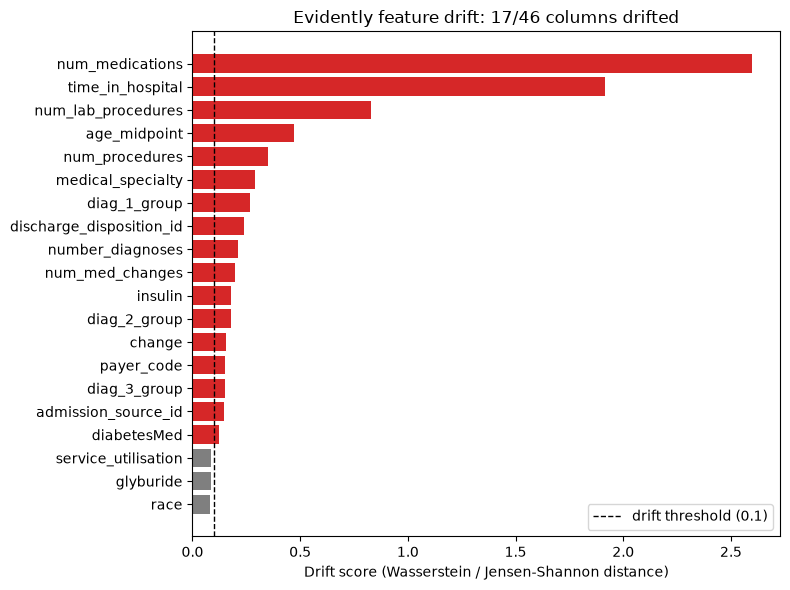

,reference_mean,current_mean
time_in_hospital,4.25,9.83
num_medications,15.74,37.50
age_midpoint,65.28,72.86
number_inpatient,0.18,0.14
number_diagnoses,7.19,8.20


In [12]:
# 4.4.1 — Feature drift (Evidently, reference vs current)
production_model = mon.load_production_model()
reference = mon.build_reference_sample(splits["X_train"])
current = mon.simulate_current_batch(splits["X_test"])

feature_result, column_drift = mon.feature_drift(reference, current)
display(pd.Series({k: feature_result[k] for k in
                   ("n_columns", "n_drifted_columns", "drift_share", "dataset_drift", "dataset_drift_rule", "report_path")},
                  name="feature drift").to_frame())
display(column_drift.head(20).round(4))

top = column_drift.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["column"], top["score"], color=np.where(top["drifted"], "tab:red", "tab:gray"))
ax.axvline(0.1, color="black", linestyle="--", linewidth=1, label="drift threshold (0.1)")
ax.set_xlabel("Drift score (Wasserstein / Jensen-Shannon distance)")
ax.set_title(f"Evidently feature drift: {feature_result['n_drifted_columns']}/{feature_result['n_columns']} columns drifted")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

compare = ["time_in_hospital", "num_medications", "age_midpoint", "number_inpatient", "number_diagnoses"]
display(pd.DataFrame({"reference_mean": reference[compare].mean(), "current_mean": current[compare].mean()}).round(2))

### 4.4.2 — Prediction drift (PSI on scores) + interpretation [2]

The Population Stability Index compares the distribution of the production model's **predicted probabilities** on the reference and current samples. It is computed over 10 bins defined by reference-score deciles:

$$\text{PSI} = \sum_{b=1}^{10} (c_b - r_b)\,\ln\frac{c_b}{r_b}$$

Here $r_b$ and $c_b$ are the reference and current shares in bin $b$. Rules of thumb: below 0.1 is stable, 0.1–0.2 is a moderate shift, above 0.2 is a significant shift. Prediction drift needs no labels, so it is available immediately; readmission labels only arrive 30 days later.

As a control, the PSI is also computed for an **unshifted** sample of the same unseen test split (`strength=0`). This shows the value expected from sampling noise alone.

2026-11-11 13:12:56,595 INFO monitoring: Prediction drift: PSI 0.167 (moderate shift)


2026-11-11 13:12:56,671 INFO monitoring: Simulated current batch (5000, 46) (strength=0.0) saved to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\data\monitoring\control_batch.csv


2026-11-11 13:12:56,742 INFO monitoring: Drift summary written to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\reports\drift_summary.json


,prediction drift
prediction_psi,0.167174
psi_interpretation,moderate shift
reference_mean_score,0.45271
current_mean_score,0.468138
reference_flag_rate,0.3362
current_flag_rate,0.3842
control_psi_unshifted_sample,0.002737


,bin_lower,bin_upper,reference_pct,current_pct,psi_contribution
0,-inf,0.3027,0.1,0.1150,0.0021
1,0.3027,0.3444,0.1,0.0262,0.0988
2,0.3444,0.3775,0.1,0.0506,0.0337
3,0.3775,0.4091,0.1,0.1188,0.0032
4,0.4091,0.4407,0.1,0.0816,0.0037
5,0.4407,0.4768,0.1,0.1260,0.0060
6,0.4768,0.5174,0.1,0.1408,0.0140
7,0.5174,0.5595,0.1,0.1084,0.0007
8,0.5595,0.6178,0.1,0.1150,0.0021
9,0.6178,inf,0.1,0.1176,0.0029


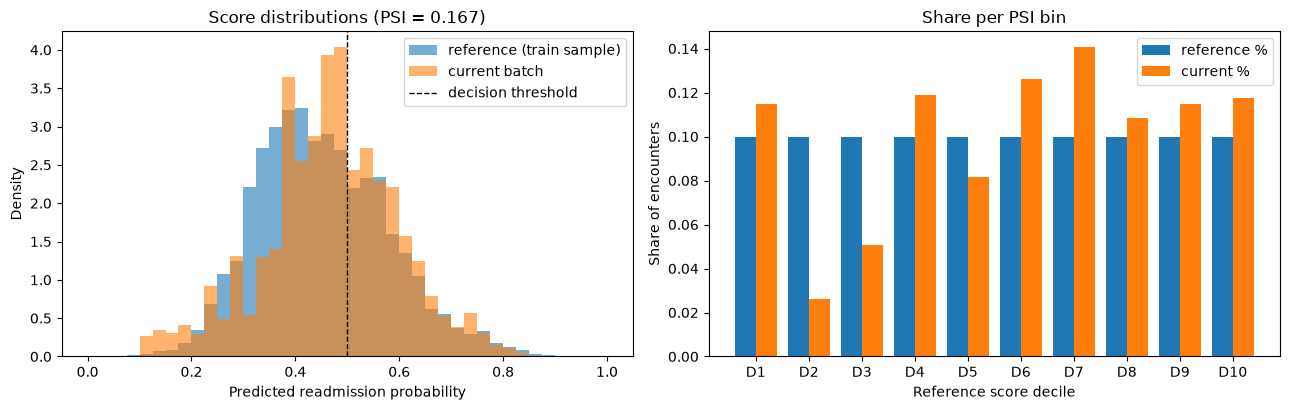

drift_summary.json written to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\reports\drift_summary.json


In [13]:
# 4.4.2 — Prediction drift (PSI on scores)
prediction_result, psi_table, reference_scores, current_scores = mon.prediction_drift(production_model, reference, current)

control = mon.simulate_current_batch(splits["X_test"], strength=0.0,
                                     path=mon.MONITORING_DATA_DIR / "control_batch.csv")
control_psi, _ = mon.population_stability_index(reference_scores, production_model.predict_proba(control)[:, 1])

drift_summary = mon.write_drift_summary(feature_result, prediction_result, len(reference), len(current),
                                        model_version=production.version)
display(pd.Series({**prediction_result, "control_psi_unshifted_sample": control_psi}, name="prediction drift")
        .to_frame().round(4))
display(psi_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(0, 1, 41)
axes[0].hist(reference_scores, bins=bins, alpha=0.6, density=True, label="reference (train sample)")
axes[0].hist(current_scores, bins=bins, alpha=0.6, density=True, label="current batch")
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1, label="decision threshold")
axes[0].set(xlabel="Predicted readmission probability", ylabel="Density",
            title=f"Score distributions (PSI = {prediction_result['prediction_psi']:.3f})")
axes[0].legend()
labels = [f"D{i + 1}" for i in range(len(psi_table))]
x = np.arange(len(psi_table))
axes[1].bar(x - 0.2, psi_table["reference_pct"], 0.4, label="reference %")
axes[1].bar(x + 0.2, psi_table["current_pct"], 0.4, label="current %")
axes[1].set_xticks(x, labels)
axes[1].set(xlabel="Reference score decile", ylabel="Share of encounters", title="Share per PSI bin")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"drift_summary.json written to {mon.DRIFT_SUMMARY_PATH}")

#### Interpretation

**Feature drift (4.4.1).** The simulated batch is a much sicker population than the reference:

- mean length of stay rose from 4.3 to 9.8 days;
- medications rose from 15.7 to 37.5;
- mean age rose from 65 to 73;
- circulatory primary diagnoses rose from 31% to 67% of encounters.

Evidently flags **17 of 46 features (drift share 0.37)**. Besides the four features the simulation weighted directly, correlated features such as lab procedures, number of diagnoses, medical specialty, discharge disposition, insulin use and medication changes drifted with them. Dataset drift is **not** declared, because 0.37 is below the 50% rule.

**Prediction drift (4.4.2).** Prediction PSI is **0.167, a moderate shift** (0.1–0.2). For comparison, an unshifted sample from the same unseen split gives a PSI of only **0.003**, so the 0.167 reflects the population change, not sampling noise.

- The mean score moved from 0.453 to 0.468.
- The share of encounters flagged high-risk at the 0.5 threshold rose from **33.6% to 38.4%**.
- Scores are not calibrated probabilities, because `scale_pos_weight` deliberately inflates them. What matters operationally is the flag rate, which drives the number of patients referred for follow-up.

**Why PSI moved less than the inputs.** Several large input shifts carry little weight in the model, while its strongest predictor, prior inpatient visits, barely changed (0.18 → 0.14 mean). Prediction drift on its own would therefore under-react to this case-mix change. A clinically important change can sit below the PSI threshold while feature drift is already broad. This is why the retraining trigger in 4.5.1 combines both kinds of signal.

**Action.** Given a drift share above 0.3 and a moderate PSI, the model should be retrained and re-validated before the shift grows, rather than left serving a population it was not trained on. Once the 30-day labels for the new batch arrive, performance (ROC-AUC, recall) should be checked directly.

## Task 4.5 — Retraining Workflow [3 Marks]

### 4.5.1 — Multi-signal retraining trigger defined [1]: Prediction PSI > 0.2 OR drift share > 0.3 OR dataset drift.

`retrain.evaluate_triggers` reads `reports/drift_summary.json` and fires if **any** of three independent signals fires:

| Signal | Source | Fires when | Why it matters |
|---|---|---|---|
| Prediction PSI | 4.4.2 | PSI > 0.2 | The model's output distribution has shifted significantly, so the risk flags it produces have changed. |
| Drift share | 4.4.1 | share of drifted features > 0.3 | A broad part of the input space has moved, even if the scores have not shifted much yet. |
| Dataset drift | 4.4.1 | Evidently dataset drift = True (≥ 50% of columns) | A whole-population change. |

Using several signals means a shift is caught whether it appears first in the inputs or in the outputs. All three are label-free, so they can fire before the 30-day outcomes needed to measure performance directly are available.

In [14]:
# 4.5.1 — Multi-signal retraining trigger: Prediction PSI > 0.2 OR drift share > 0.3 OR dataset drift
print("Thresholds:", retrain.TRIGGER_THRESHOLDS, "| dataset drift rule:", feature_result["dataset_drift_rule"])
trigger = retrain.evaluate_triggers(json.loads(mon.DRIFT_SUMMARY_PATH.read_text(encoding="utf-8")))
display(pd.DataFrame(trigger["signals"]).T.rename_axis("signal"))
print(f"Fired signals: {trigger['fired_signals']} -> retrain = {trigger['should_retrain']}")

Thresholds: {'prediction_psi': 0.2, 'drift_share': 0.3} | dataset drift rule: drifted-column share >= 0.5


,value,threshold,fired
signal,,,
prediction_psi,0.1672,> 0.2,False
drift_share,0.3696,> 0.3,True
dataset_drift,False,== True,False


Fired signals: ['drift_share'] -> retrain = True


### 4.5.2 — Retraining workflow runs + re-registers + decision record [2]

`retrain.run_retraining(drift_summary)` is the workflow that a scheduler (cron, Airflow or a GitHub Actions schedule) would call after each monitoring run. The same workflow is available from the command line as `python retrain.py`.

1. **Trigger.** It evaluates the trigger. If no signal fires, it writes a `no_retrain` decision and stops.
2. **Retrain.** It clones the production pipeline (same preprocessing and hyperparameters) and refits it on train + validation, with `scale_pos_weight` recomputed for the larger set. In production, the newly labelled recent encounters would be appended here.
3. **Champion vs challenger.** The current champion (`@production`) and the candidate are both evaluated on the held-out test split.
4. **Re-register.** The candidate is logged as an MLflow run (parameters, metrics, the drift summary as an artifact, and the model) and registered as a **new version** of `hospital-readmission-30d-classifier`, tagged with the trigger and decision id.
5. **Promote or keep.** The `@production` alias moves to the candidate only if its test ROC-AUC is at least the champion's minus 0.005. When promoted, the new model is re-exported to `./model` for the API; rebuilding the image (4.2.2) ships it in the container.
6. **Decision record.** A JSON record of the decision is appended to `logs/retraining_decisions.jsonl` (signals, metrics, versions, reason).

In [15]:
# 4.5.2 — Retraining workflow runs + re-registers + decision record
decision = retrain.run_retraining(json.loads(mon.DRIFT_SUMMARY_PATH.read_text(encoding="utf-8")))

print(f"Decision: {decision['decision']}\nReason:   {decision['reason']}\n")
display(pd.DataFrame({"champion (v" + decision["champion_version"] + ")": decision.get("champion_test_metrics", {}),
                      "candidate (v" + str(decision.get("candidate_version")) + ")": decision.get("candidate_test_metrics", {})}))

print("\nDecision record (logs/retraining_decisions.jsonl):")
print(json.dumps({k: v for k, v in decision.items() if k not in ("champion_test_metrics", "candidate_test_metrics")},
                 indent=2, default=str))

2026-11-11 13:12:57,312 INFO retraining: Retraining triggered by ['drift_share'] (forced=False)


Registered model 'hospital-readmission-30d-classifier' already exists. Creating a new version of this model...


Created version '2' of model 'hospital-readmission-30d-classifier'.



2026-11-11 13:13:17,390 INFO monitoring: Exported hospital-readmission-30d-classifier v2 (@production) to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\model


2026-11-11 13:13:17,392 INFO retraining: Decision record aeedd582-bec5-4656-8d07-ab529229dab1: promoted


Decision: promoted
Reason:   Candidate test ROC-AUC 0.6526 >= champion 0.6556 - 0.005; alias moved to v2.



,champion (v1),candidate (v2)
roc_auc,0.6556,0.6526
pr_auc,0.1799,0.1854
recall,0.5292,0.5473
precision,0.1422,0.1436
f1,0.2242,0.2275
accuracy,0.6716,0.6667



Decision record (logs/retraining_decisions.jsonl):
{
  "decision_id": "aeedd582-bec5-4656-8d07-ab529229dab1",
  "timestamp": "2026-11-11T07:42:57.312878+00:00",
  "drift_summary_generated_at": "2026-11-11T07:42:56.740740+00:00",
  "trigger": {
    "signals": {
      "prediction_psi": {
        "value": 0.1672,
        "threshold": "> 0.2",
        "fired": false
      },
      "drift_share": {
        "value": 0.3696,
        "threshold": "> 0.3",
        "fired": true
      },
      "dataset_drift": {
        "value": false,
        "threshold": "== True",
        "fired": false
      }
    },
    "fired_signals": [
      "drift_share"
    ],
    "should_retrain": true
  },
  "forced": false,
  "champion_version": "1",
  "decision": "promoted",
  "reason": "Candidate test ROC-AUC 0.6526 >= champion 0.6556 - 0.005; alias moved to v2.",
  "candidate_version": "2",
  "candidate_run_id": "d3690def3a854c608450b157728966be",
  "production_version_after": "2",
  "training_rows": 59477,
  "e

In [16]:
# 4.5.2 (continued) — registry after retraining, and the served model
display(mon.registry_history()[["aliases", "model_family", "trained_by", "val_roc_auc", "test_roc_auc", "run_id", "created"]])
served = json.loads((ROOT / "model" / "model_info.json").read_text(encoding="utf-8"))
print(f"@production -> v{mon.production_version().version}; ./model (served by the API) holds v{served['model_version']}")

,aliases,model_family,trained_by,val_roc_auc,test_roc_auc,run_id,created
version,,,,,,,
2,production,xgboost,retrain.py,None,0.6526,d3690def3a854c608450b157728966be,2026-11-11 07:43:17
1,-,xgboost,stage3_notebook,0.6650,0.6556,c10bb43f1120428d8f1665253cd6d577,2026-11-08 07:22:12


@production -> v2; ./model (served by the API) holds v2


## Task 4.6 — Logging & Governance [4 Marks]

### 4.6.1 — Prediction logging [2]

For every `/predict` call the API appends one JSON line to `logs/predictions.jsonl` (configurable with `PREDICTION_LOG_PATH`). Each record contains:

- the timestamp and request id;
- the model name and version that served the request;
- the probability, prediction, risk label and threshold;
- the latency;
- the full validated input features.

This gives an audit trail per decision, and the logged inputs and scores are what a production monitoring job would use as the "current" batch for 4.4. Monitoring and retraining steps are logged separately to `logs/monitoring.log`.

In [17]:
# 4.6.1 — Prediction logging
prediction_log = pd.DataFrame([json.loads(line) for line in PREDICTION_LOG.read_text(encoding="utf-8").splitlines()])
print(f"{len(prediction_log)} logged predictions in {PREDICTION_LOG.relative_to(ROOT)}; "
      f"each record has {prediction_log['features'].iloc[0].__len__()} input features")
display(prediction_log.drop(columns="features").tail(5))
display(pd.Series({
    "requests": len(prediction_log),
    "model versions served": ", ".join(sorted(prediction_log["model_version"].unique())),
    "mean probability": round(prediction_log["readmission_probability"].mean(), 4),
    "high-risk rate": round(prediction_log["prediction"].mean(), 4),
    "latency p50 (ms)": prediction_log["latency_ms"].median(),
    "latency p95 (ms)": prediction_log["latency_ms"].quantile(0.95),
}, name="prediction log summary").to_frame())

print("Latest record (features truncated):")
latest = prediction_log.iloc[-1].to_dict()
latest["features"] = dict(list(latest["features"].items())[:8]) | {"...": "..."}
print(json.dumps(latest, indent=2, default=str))

print("\nlogs/monitoring.log (tail):")
print("\n".join(mon.MONITORING_LOG_PATH.read_text(encoding="utf-8").splitlines()[-6:]))

51 logged predictions in logs\predictions.jsonl; each record has 44 input features


,timestamp,request_id,model_name,model_version,readmission_probability,prediction,risk_label,threshold,latency_ms
46,2026-11-11T07:41:17.776583+00:00,202b7a99-3c0c-4d40-9687-d0f8061d8706,hospital-readmission-30d-classifier,1,0.597957,1,high risk,0.5,43.08
47,2026-11-11T07:41:17.824677+00:00,d32e6bc2-98fd-4c53-b3ae-bfc0d26b0b2b,hospital-readmission-30d-classifier,1,0.339320,0,low risk,0.5,42.65
48,2026-11-11T07:41:17.873680+00:00,deedbcc7-8752-439b-9bf2-9797312740a3,hospital-readmission-30d-classifier,1,0.392104,0,low risk,0.5,42.20
49,2026-11-11T07:41:17.920442+00:00,927487c8-5f4c-4fff-b13b-3532480dc271,hospital-readmission-30d-classifier,1,0.557757,1,high risk,0.5,40.65
50,2026-11-11T07:41:17.968516+00:00,d354a675-634e-49fa-a4f4-9b70e052b109,hospital-readmission-30d-classifier,1,0.369167,0,low risk,0.5,41.78


,prediction log summary
requests,51
model versions served,1
mean probability,0.4645
high-risk rate,0.3529
latency p50 (ms),42.26
latency p95 (ms),56.72


Latest record (features truncated):
{
  "timestamp": "2026-11-11T07:41:17.968516+00:00",
  "request_id": "d354a675-634e-49fa-a4f4-9b70e052b109",
  "model_name": "hospital-readmission-30d-classifier",
  "model_version": "1",
  "readmission_probability": 0.369167,
  "prediction": 0,
  "risk_label": "low risk",
  "threshold": 0.5,
  "latency_ms": 41.78,
  "features": {
    "race": "AfricanAmerican",
    "gender": "Male",
    "age": "[50-60)",
    "admission_type_id": 2,
    "discharge_disposition_id": 1,
    "admission_source_id": 4,
    "time_in_hospital": 1,
    "payer_code": null,
    "...": "..."
  }
}

logs/monitoring.log (tail):
2026-11-11 13:12:56,595 INFO monitoring: Prediction drift: PSI 0.167 (moderate shift)
2026-11-11 13:12:56,671 INFO monitoring: Simulated current batch (5000, 46) (strength=0.0) saved to C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\data\monitoring\control_batch.csv
2026-11-11 13:12:56,742 INFO monitoring: Drift summary writte

### 4.6.2 — Model governance (registry history + alias + pinned deps) [2]

- **Registry history.** Every version of `hospital-readmission-30d-classifier` is kept with its source run, tags (model family, metrics, who or what trained it, trigger and decision id) and a description. Older versions are never overwritten, so any of them can be reloaded or rolled back to.
- **Alias.** Serving resolves `@production`, never a hard-coded version. Promotion and rollback are a single alias move, recorded in the decision log.
- **Pinned dependencies.** `requirements.txt` pins every package `==` (and `requirements-api.txt` pins the container runtime), so training, CI and serving use identical library versions. MLflow also stores the model's own `requirements.txt` and `conda.yaml` with each version.

In [18]:
# 4.6.2 — Model governance (registry history + alias + pinned deps)
from mlflow import MlflowClient

client = mon.configure_mlflow()
registered = client.get_registered_model(mon.REGISTERED_MODEL_NAME)
print(f"Registered model: {registered.name}\nDescription: {registered.description}")
print(f"Aliases: {registered.aliases}\n")

history = mon.registry_history(client)
display(history[["aliases", "model_family", "trained_by", "status", "run_id", "created", "description"]])

alias_version = client.get_model_version_by_alias(mon.REGISTERED_MODEL_NAME, mon.PRODUCTION_ALIAS)
print(f"models:/{mon.REGISTERED_MODEL_NAME}@{mon.PRODUCTION_ALIAS} -> version {alias_version.version} "
      f"(run {alias_version.run_id}, tags {alias_version.tags})\n")

decisions = retrain.read_decisions()
display(decisions[["timestamp", "decision", "champion_version", "candidate_version", "production_version_after", "reason"]])

pins = mon.pinned_dependencies()
display(pins)
print(f"{pins['matches'].sum()}/{len(pins)} pinned packages match the installed versions")
assert pins["matches"].all()
print("\nModel-level requirements stored by MLflow with the production version (./model/requirements.txt):")
print((ROOT / "model" / "requirements.txt").read_text(encoding="utf-8"))

Registered model: hospital-readmission-30d-classifier
Description: Predicts 30-day readmission risk for diabetic inpatients (Diabetes 130-US Hospitals). Full preprocessing + classifier sklearn Pipeline; input = one encounter's features.
Aliases: {'production': 2}



,aliases,model_family,trained_by,status,run_id,created,description
version,,,,,,,
2,production,xgboost,retrain.py,READY,d3690def3a854c608450b157728966be,2026-11-11 07:43:17,Retrained by retrain.py (promoted). Candidate ...
1,-,xgboost,stage3_notebook,READY,c10bb43f1120428d8f1665253cd6d577,2026-11-08 07:22:12,XGBoost selected by validation ROC-AUC = 0.665...


models:/hospital-readmission-30d-classifier@production -> version 2 (run d3690def3a854c608450b157728966be, tags {'model_family': 'xgboost', 'trained_by': 'retrain.py', 'test_roc_auc': '0.6526', 'test_recall': '0.5473', 'trigger_signals': 'drift_share', 'decision_id': 'aeedd582-bec5-4656-8d07-ab529229dab1'})



,timestamp,decision,champion_version,candidate_version,production_version_after,reason
0,2026-11-11T07:42:57.312878+00:00,promoted,1,2,2,Candidate test ROC-AUC 0.6526 >= champion 0.65...


,pinned,installed,matches
package,,,
matplotlib,3.11.2,3.11.2,True
numpy,2.5.4,2.5.4,True
pandas,2.3.3,2.3.3,True
seaborn,0.13.2,0.13.2,True
scipy,1.18.1,1.18.1,True
scikit-learn,1.9.1,1.9.1,True
xgboost,3.4.1,3.4.1,True
mlflow,3.18.0,3.18.0,True
skops,0.16.0,0.16.0,True


16/16 pinned packages match the installed versions

Model-level requirements stored by MLflow with the production version (./model/requirements.txt):
mlflow==3.18.0
numpy==2.5.4
pandas==2.3.3
psutil==7.2.2
pytest==9.2.0
rich==15.0.0
scikit-learn==1.9.1
scipy==1.18.1
skops==0.16.0
xgboost==3.4.1
